# Projet de scoring crédit — prédire le défaut grave de paiement

## Objectif du projet

Une banque reçoit des demandes de carte de crédit. Pour chaque demande, elle veut savoir si le client risque de connaître un **retard de paiement grave**. Ce notebook construit un modèle d'apprentissage supervisé qui donne un **score de risque** à chaque demande, puis une **recommandation** (accord ou refus) destinée à un analyste crédit.

Le modèle est ensuite utilisé dans l'application **NovaScore** (`app.py`).

## Le fil conducteur : une question par étape

Chaque étape répond à une question, et la réponse prépare l'étape suivante.

| Étape | Question à laquelle elle répond |
|---|---|
| 1 — Business Understanding | Que cherche-t-on à prédire, et comment saura-t-on si le modèle est bon ? |
| 2 — Data Collection | Comment construire la variable à prédire à partir des données disponibles ? |
| 3 — EDA | Les données sont-elles fiables ? Que révèlent-elles sur le défaut ? |
| 4 — Data Cleaning | Que faut-il corriger ou préparer avant de modéliser ? |
| 5 — Data Preprocessing | Comment rendre les variables utilisables par les algorithmes ? |
| 6 — Feature Engineering | Quelles variables donner au modèle, et sous quelle forme ? |
| 7 — Data Splitting | Comment évaluer le modèle de façon honnête ? |
| 8 — Model Training | Quel algorithme, avec quels hyperparamètres ? |
| 9 — Model Evaluation | Quel modèle retenir, et à partir de quel score signaler un dossier ? |
| 10 — Explainability & Saving | Que vaut réellement le modèle, et sur quoi s'appuie-t-il ? |
| 11 et 12 — Application | Comment le modèle est-il mis à disposition du métier ? |

## Compétences mobilisées

| Compétence | Où dans le notebook |
|---|---|
| **C3.1** — Rendre exploitable un jeu de données (valeurs manquantes, variable à prédire) | Étapes 2 à 6 |
| **C3.2** — Organiser les données en jeux d'entraînement et de test | Étape 7 |
| **C3.3** — Exploiter plusieurs modèles d'apprentissage supervisé | Étape 8 |
| **A3.3** — Choisir des métriques adaptées et comparer les modèles | Étapes 1 et 9 |
| **C3.5** — Améliorer les performances : qualité des données, pénalisation, Grid Search, méthodes d'ensemble, rééchantillonnage, réduction du surapprentissage | Étapes 3, 4, 7, 8 et 9 |

**Données.** Les deux fichiers sources (`application_record.csv` et `credit_record.csv`) sont chargés dans une base **PostgreSQL** par `installer_base.py`. Le notebook lit ses données dans cette base, avec un compte en **lecture seule** (étape 2).

## Étape 0 — Environnement

**Pourquoi cette étape ?** Pour que le notebook et l'application s'exécutent avec les mêmes librairies, sur n'importe quel poste.

Dans le terminal VS Code, avec l'environnement `novalis` activé :

```cmd
python -m pip install -r requirements-notebook.txt
python installer_base.py
```

La seconde commande crée la base PostgreSQL `novascore`, y charge les deux fichiers CSV et applique les droits d'accès. Les paramètres de connexion (serveur, mots de passe) sont dans le fichier `.env`, qui n'est jamais partagé.

Structure du projet :

```text
Scoring_Credit_Projet_Complet/
├── application_record.csv   ← une ligne par demande (profil du client)
├── credit_record.csv        ← l'historique mensuel de remboursement des clients
├── .env                     ← paramètres de connexion à PostgreSQL (non partagé)
├── installer_base.py        ← création et chargement de la base PostgreSQL
├── sql/                     ← scripts SQL : rôles, tables, vue de modélisation, index, droits
├── Scoring_Credit.ipynb     ← ce notebook : préparation, modélisation, évaluation
├── app.py                   ← l'application NovaScore qui utilise le modèle
├── requirements.txt         ← les librairies de l'application (versions fixées)
├── requirements-notebook.txt ← les librairies du notebook (en plus)
└── models/                  ← le modèle, le seuil et les résultats sauvegardés (étape 10)
```

La cellule suivante importe les librairies : `psycopg` pour la connexion à PostgreSQL, `pandas` et `numpy` pour les données, `scikit-learn` pour la préparation, la validation et les métriques, `xgboost` et `lightgbm` pour les modèles de boosting, `shap` pour l'explicabilité, `matplotlib` et `seaborn` pour les graphiques.

In [1]:
import os
import joblib
import psycopg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import (
    StratifiedKFold, StratifiedGroupKFold, GridSearchCV, cross_val_predict, cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

pd.set_option("display.max_columns", None)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Étape 1 — Business Understanding

> **Question :** que cherche-t-on à prédire, et comment saura-t-on si le modèle est bon ?

**Pourquoi cette étape ?** Le choix de la cible et des métriques conditionne tout le reste. Une métrique mal choisie peut faire paraître excellent un modèle inutile.

**Problème métier.** Repérer, au moment de la demande, les dossiers associés à un risque de retard de paiement grave, pour que l'analyste les examine en priorité.

**Variable à prédire : `defaut`.** C'est une classification binaire :
- `1` : le client présente au moins un retard de 90 jours ou plus (statuts `3`, `4` ou `5`) dans son historique ;
- `0` : aucun retard de cette gravité.

Cette cible décrit un défaut **observé dans l'historique disponible**. Elle ne prouve pas que l'on prédit un défaut futur : c'est une limite à garder en tête.

**Coût des erreurs.**
- *Faux négatif* (un futur mauvais payeur non signalé) : perte financière, coût élevé.
- *Faux positif* (un bon client signalé) : examen supplémentaire par l'analyste, coût plus faible.

**Métriques retenues.**
- **Average Precision (AP)**, métrique principale. Le défaut grave est rare : l'AP mesure la capacité du modèle à placer les défauts en tête de classement. Elle se compare au **taux de défaut**, qui est l'AP d'un modèle tirant au hasard.
- **ROC-AUC**, en complément : probabilité que le modèle donne un score plus élevé à un défaut qu'à un non-défaut (0,5 = hasard).
- **Recall, Precision, F1 et F2** au seuil de décision. Le F2 donne plus de poids au Recall, ce qui traduit le coût plus élevé d'un défaut non détecté (étape 9).
- **L'Accuracy** est affichée, mais elle n'a pas de sens ici : avec moins de 1 % de défauts, un modèle qui répond toujours « pas de défaut » aurait plus de 99 % d'accuracy sans détecter un seul cas.

**Lien avec la suite.** La rareté du défaut, annoncée ici, guide plusieurs choix : la stratification (étape 7), la pondération des classes (étape 8) et le choix du seuil (étape 9).

## Étape 2 — Data Collection

> **Question :** comment construire la variable à prédire à partir des données disponibles ?

**Pourquoi cette étape ?** Les données sources ne contiennent pas directement la cible. La table `sources.application_record` décrit le client au moment de la demande (les variables explicatives). La table `sources.credit_record` contient, mois par mois, le statut de remboursement de chaque client. C'est de cet historique qu'on déduit `defaut`.

**D'où viennent les données ?** D'une base **PostgreSQL**, alimentée à partir des deux fichiers CSV par `installer_base.py` (contrôle qualité, chargement, index, droits d'accès). Le notebook s'y connecte avec le rôle **`novascore_lecture`** : il peut lire les données, mais ni les modifier ni voir les données personnelles de l'application. Les mots de passe sont lus dans le fichier `.env`, jamais écrits dans le notebook.

**Les règles de construction de la cible sont écrites en SQL**, dans la vue `sources.v_donnees_modelisation` (`sql/02_tables.sql`) :
1. elle écarte les identifiants présents plusieurs fois dans les demandes : on ne saurait pas quelle ligne relier à l'historique ;
2. elle ne garde que les demandes **qui ont un historique de crédit** (jointure interne). Pour une demande sans historique, on ne sait pas si le client a été en défaut : sa cible est inconnue, elle ne peut donc pas servir à l'apprentissage ;
3. elle construit la cible : `defaut = 1` si le client a au moins un statut `3`, `4` ou `5`.

Placer ces règles dans la base garantit que tout utilisateur des données (notebook, reporting) obtient exactement le même jeu de modélisation.

**Ce que fait le code.**
1. Il ouvre la connexion en lecture seule.
2. Il compte, par des requêtes SQL, les volumes qui expliquent le passage des données brutes au jeu de modélisation.
3. Il lit la vue, dans l'ordre des fichiers d'origine (`ORDER BY ligne`), et redonne aux colonnes leurs noms d'origine en majuscules.


In [2]:
# Paramètres de connexion lus dans le fichier .env (les mots de passe ne sont jamais écrits dans le notebook)
config = {}
with open(".env", encoding="utf-8-sig") as fichier:
    for ligne in fichier:
        ligne = ligne.strip()
        if ligne and not ligne.startswith("#") and "=" in ligne:
            cle, valeur = ligne.split("=", 1)
            config[cle.strip()] = valeur.strip().strip('"').strip("'")

# Connexion avec le rôle en lecture seule
connexion = psycopg.connect(
    host=config.get("PG_HOTE", "localhost"),
    port=config.get("PG_PORT", "5432"),
    dbname=config.get("NOVASCORE_BASE", "novascore"),
    user="novascore_lecture",
    password=config["NOVASCORE_LECTURE_MDP"],
    sslmode=config.get("PG_SSLMODE", "prefer"),
)

def lire_sql(requete):
    """Exécute une requête SQL et renvoie le résultat sous forme de DataFrame."""
    with connexion.cursor() as curseur:
        curseur.execute(requete)
        return pd.DataFrame(curseur.fetchall(), columns=[c.name for c in curseur.description])

# Volumes : des données brutes au jeu de modélisation
volumes = lire_sql("""
    WITH ids_doublons AS (
        SELECT id FROM sources.application_record GROUP BY id HAVING COUNT(*) > 1
    )
    SELECT
        (SELECT COUNT(*) FROM sources.application_record) AS demandes,
        (SELECT COUNT(*) FROM sources.credit_record)      AS lignes_historique,
        (SELECT COUNT(*) FROM ids_doublons)               AS identifiants_en_double,
        (SELECT COUNT(*) FROM sources.application_record a
          WHERE a.id NOT IN (SELECT id FROM ids_doublons)
            AND NOT EXISTS (SELECT 1 FROM sources.credit_record c WHERE c.id = a.id)) AS demandes_sans_historique
""")
print("Demandes (sources.application_record) :", volumes.loc[0, "demandes"])
print("Historique de crédit (sources.credit_record) :", volumes.loc[0, "lignes_historique"])
print("Identifiants en double supprimés :", volumes.loc[0, "identifiants_en_double"])
print("Demandes sans historique de crédit (exclues) :", volumes.loc[0, "demandes_sans_historique"])

# Jeu de modélisation : la vue applique les règles de construction de la cible
data = lire_sql("SELECT * FROM sources.v_donnees_modelisation ORDER BY ligne")
connexion.close()

data = data.drop(columns="ligne")                                          # clé technique de la base
data.columns = [c if c == "defaut" else c.upper() for c in data.columns]   # noms d'origine des colonnes
data["OCCUPATION_TYPE"] = data["OCCUPATION_TYPE"].fillna(np.nan)           # NULL SQL → valeur manquante pandas

# Variables du profil client (tout sauf l'identifiant et la cible)
colonnes_profil = [c for c in data.columns if c not in ("ID", "defaut")]

print("Dimensions du jeu de modélisation :", data.shape)
print(data["defaut"].value_counts())
print("Taux de défaut observé :", round(data["defaut"].mean() * 100, 4), "%")


Demandes (sources.application_record) : 438557
Historique de crédit (sources.credit_record) : 1048575
Identifiants en double supprimés : 47
Demandes sans historique de crédit (exclues) : 402006


Dimensions du jeu de modélisation : (36457, 19)
defaut
0    36155
1      302
Name: count, dtype: int64
Taux de défaut observé : 0.8284 %


#### Lecture des résultats — Étape 2

- La table des demandes contient **438 557 lignes** et celle de l'historique **1 048 575 lignes** : un client a une ligne par mois d'historique. Ce sont exactement les volumes des fichiers CSV : le chargement dans la base n'a perdu aucune ligne.
- **47 identifiants** apparaissent plusieurs fois dans les demandes et sont écartés.
- **402 006 demandes n'ont aucun historique de crédit.** Leur cible est inconnue : elles ne peuvent servir ni à entraîner ni à évaluer le modèle.
- Le jeu de modélisation compte donc **36 457 demandes**, dont **302 défauts graves**, soit un taux de défaut de **0,83 %**. Le jeu compte 19 colonnes : l'identifiant, 17 variables du profil client et la cible.

**Ce que cela implique.** Le défaut grave est un événement **rare** : environ 1 demande sur 120. Ce déséquilibre guide la suite : métriques adaptées (étape 1), découpage stratifié (étape 7), pondération des classes (étape 8) et choix du seuil (étape 9). Avec 302 défauts seulement, chaque pli de validation en contiendra peu : il faudra aussi regarder la **stabilité** des scores, pas seulement leur moyenne.

## Étape 3 — EDA (analyse exploratoire)

> **Question :** les données sont-elles fiables, et que révèlent-elles sur le défaut ?

**Pourquoi cette étape ?** Avant de modéliser, il faut connaître ses données : valeurs manquantes, doublons, valeurs aberrantes, déséquilibre de la cible, liens entre variables. Chaque constat de l'EDA déclenche une décision dans les étapes suivantes.

**Ce que fait le code.**
- Il affiche la structure du jeu de données et le nombre de valeurs manquantes par variable.
- Il recherche les doublons, avec et sans l'identifiant. Deux identifiants différents peuvent en effet décrire exactement le même profil.
- Il contrôle la variable `DAYS_EMPLOYED`, qui contient une valeur particulière (`365243`), et la variable constante `FLAG_MOBIL`.
- Il affiche la répartition de la cible et la distribution de quelques variables selon la cible.
- Il calcule la **matrice de corrélation** des variables numériques et de la cible. La valeur `365243` de `DAYS_EMPLOYED` est exclue du calcul, car ce n'est pas une durée et elle fausserait la corrélation.

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,defaut
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0,0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0,0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0,0


<class 'pandas.DataFrame'>
RangeIndex: 36457 entries, 0 to 36456
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   36457 non-null  int64  
 1   CODE_GENDER          36457 non-null  str    
 2   FLAG_OWN_CAR         36457 non-null  str    
 3   FLAG_OWN_REALTY      36457 non-null  str    
 4   CNT_CHILDREN         36457 non-null  int64  
 5   AMT_INCOME_TOTAL     36457 non-null  float64
 6   NAME_INCOME_TYPE     36457 non-null  str    
 7   NAME_EDUCATION_TYPE  36457 non-null  str    
 8   NAME_FAMILY_STATUS   36457 non-null  str    
 9   NAME_HOUSING_TYPE    36457 non-null  str    
 10  DAYS_BIRTH           36457 non-null  int64  
 11  DAYS_EMPLOYED        36457 non-null  int64  
 12  FLAG_MOBIL           36457 non-null  int64  
 13  FLAG_WORK_PHONE      36457 non-null  int64  
 14  FLAG_PHONE           36457 non-null  int64  
 15  FLAG_EMAIL           36457 non-null  int64  
 1

OCCUPATION_TYPE        11323
CODE_GENDER                0
ID                         0
FLAG_OWN_CAR               0
FLAG_OWN_REALTY            0
AMT_INCOME_TOTAL           0
CNT_CHILDREN               0
NAME_EDUCATION_TYPE        0
NAME_FAMILY_STATUS         0
NAME_HOUSING_TYPE          0
NAME_INCOME_TYPE           0
DAYS_BIRTH                 0
DAYS_EMPLOYED              0
FLAG_WORK_PHONE            0
FLAG_MOBIL                 0
FLAG_PHONE                 0
FLAG_EMAIL                 0
CNT_FAM_MEMBERS            0
defaut                     0
dtype: int64

Doublons (toutes colonnes, ID compris) : 0
Doublons hors ID (même profil, ID différent) : 26729
Profils distincts : 9728 pour 36457 lignes
Lignes avec DAYS_EMPLOYED = 365243 : 6135
NAME_INCOME_TYPE
Pensioner    6135
Name: count, dtype: int64
Valeurs de FLAG_MOBIL : [1]
OCCUPATION_TYPE manquant, par type de revenu :
NAME_INCOME_TYPE
Pensioner               6139
Working                 3197
Commercial associate    1438
State servant            548
Student                    1
Name: count, dtype: int64
Répartition de la cible :


,Nombre
Classe,
0,36155
1,302


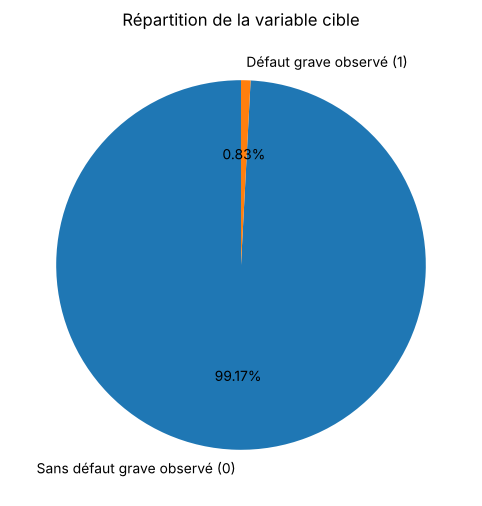

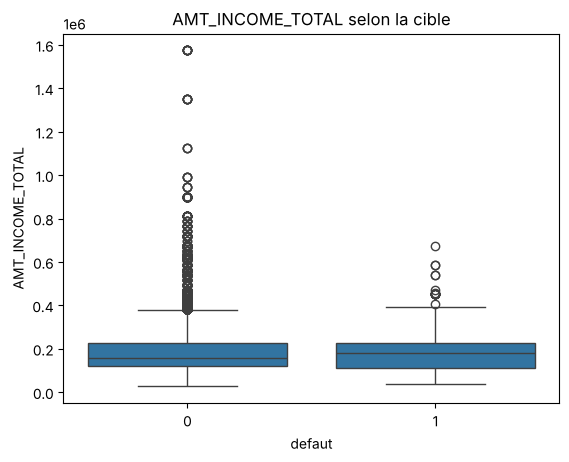

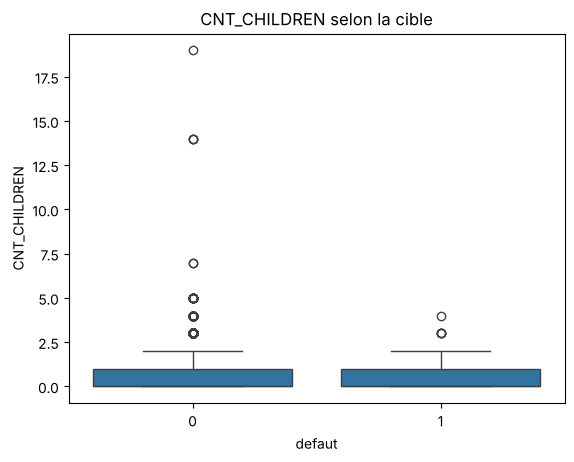

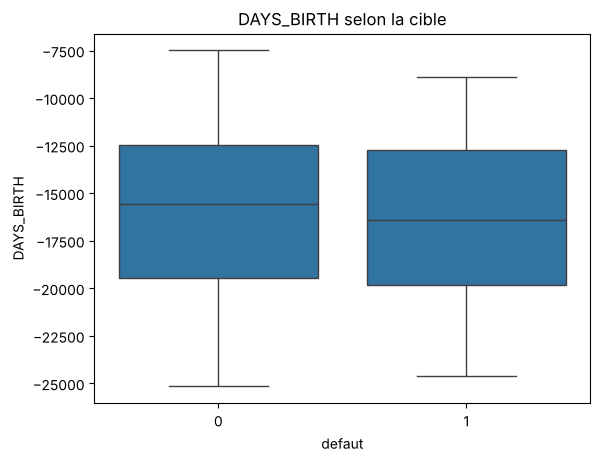

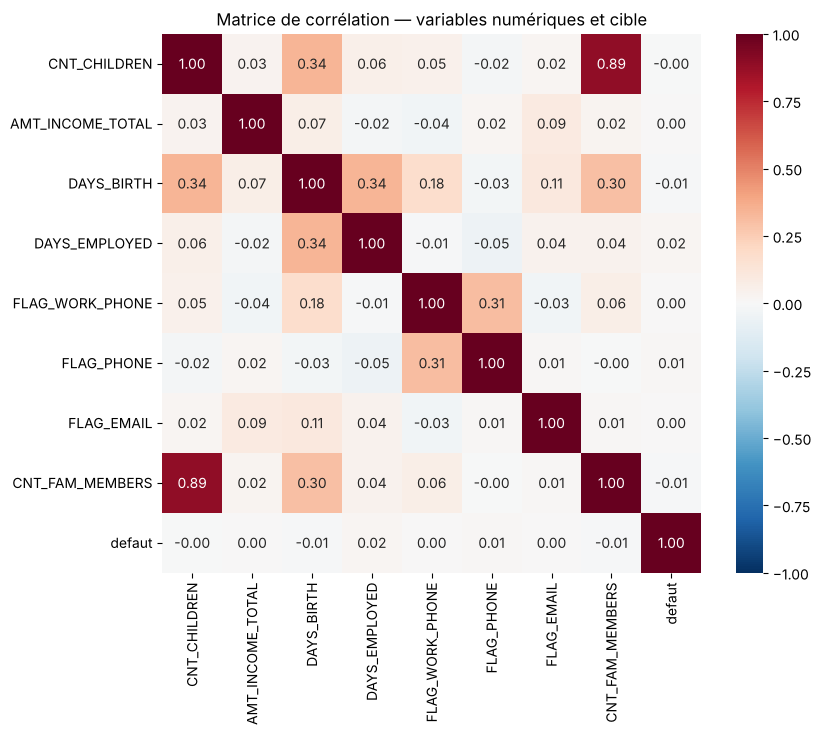

Corrélation de chaque variable avec la cible :
DAYS_EMPLOYED       0.019
CNT_FAM_MEMBERS    -0.010
DAYS_BIRTH         -0.010
FLAG_PHONE          0.008
AMT_INCOME_TOTAL    0.004
CNT_CHILDREN       -0.004
FLAG_WORK_PHONE     0.004
FLAG_EMAIL          0.003
Name: defaut, dtype: float64


In [3]:
display(data.head())
data.info()

print("Valeurs manquantes les plus fréquentes :")
display(data.isna().sum().sort_values(ascending=False).head(20))

print("Doublons (toutes colonnes, ID compris) :", data.duplicated().sum())
print("Doublons hors ID (même profil, ID différent) :", data.duplicated(subset=colonnes_profil).sum())
print("Profils distincts :", data[colonnes_profil].drop_duplicates().shape[0], "pour", len(data), "lignes")

print("Lignes avec DAYS_EMPLOYED = 365243 :", (data["DAYS_EMPLOYED"] == 365243).sum())
print(data.loc[data["DAYS_EMPLOYED"] == 365243, "NAME_INCOME_TYPE"].value_counts())
print("Valeurs de FLAG_MOBIL :", data["FLAG_MOBIL"].unique())
print("OCCUPATION_TYPE manquant, par type de revenu :")
print(data.loc[data["OCCUPATION_TYPE"].isna(), "NAME_INCOME_TYPE"].value_counts())

print("Répartition de la cible :")
repartition = data["defaut"].value_counts().sort_index()
display(repartition.rename_axis("Classe").to_frame("Nombre"))

plt.figure(figsize=(6, 6))
plt.pie(
    repartition.values,
    labels=["Sans défaut grave observé (0)", "Défaut grave observé (1)"],
    autopct="%1.2f%%",
    startangle=90
)
plt.title("Répartition de la variable cible")
plt.show()

for colonne in ["AMT_INCOME_TOTAL", "CNT_CHILDREN", "DAYS_BIRTH"]:
    if colonne in data.columns:
        sns.boxplot(data=data, x="defaut", y=colonne)
        plt.title(colonne + " selon la cible")
        plt.show()


# Matrice de corrélation des variables numériques et de la cible
colonnes_corr = ["CNT_CHILDREN", "AMT_INCOME_TOTAL", "DAYS_BIRTH", "DAYS_EMPLOYED",
                 "FLAG_WORK_PHONE", "FLAG_PHONE", "FLAG_EMAIL", "CNT_FAM_MEMBERS", "defaut"]
donnees_corr = data[colonnes_corr].copy()
donnees_corr["DAYS_EMPLOYED"] = donnees_corr["DAYS_EMPLOYED"].replace(365243, np.nan)  # code retraité exclu
matrice_corr = donnees_corr.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(matrice_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True)
plt.title("Matrice de corrélation — variables numériques et cible")
plt.show()

print("Corrélation de chaque variable avec la cible :")
print(matrice_corr["defaut"].drop("defaut").sort_values(key=abs, ascending=False).round(3))

#### Lecture des résultats — Étape 3

**Valeurs manquantes.** Une seule variable en contient : `OCCUPATION_TYPE` (métier), avec **11 323 valeurs manquantes**, soit 31 % des lignes. La répartition par type de revenu montre que **6 139 d'entre elles concernent des retraités** : un retraité n'a logiquement plus de métier. La valeur manquante est donc porteuse de sens.
→ *Étape 5 : on la remplace par une catégorie `Inconnu`.*

**Doublons.** Aucun doublon exact (avec l'identifiant), mais **26 729 lignes reprennent exactement le profil d'une autre**. Les 36 457 lignes ne correspondent qu'à **9 728 profils distincts**, soit environ 3,7 lignes par profil.
→ *Étapes 4 et 7 : clé `GROUPE_PROFIL` et découpage groupé, pour que le modèle ne soit jamais évalué sur un profil qu'il a déjà vu.*

**Valeur aberrante.** **6 135 lignes** ont `DAYS_EMPLOYED = 365243` (environ 1 000 ans d'ancienneté), et toutes sont des retraités. C'est un code, pas une durée.
→ *Étape 6 : indicateur `SANS_EMPLOI` et ancienneté mise à 0.*

**Variable constante.** `FLAG_MOBIL` vaut 1 pour tous les clients : elle n'apporte aucune information.
→ *Étape 6 : variable retirée.*

**Cible.** **36 155 non-défauts pour 302 défauts.** Le diagramme circulaire rend visible ce déséquilibre extrême.

**Distributions selon la cible.**
- *Revenu* : les médianes sont proches dans les deux groupes. Les revenus très élevés (au-delà d'environ 700 000) n'apparaissent que chez les non-défauts, mais ils sont rares.
- *Nombre d'enfants* : la plupart des clients ont 0 ou 1 enfant, avec la même distribution dans les deux groupes. Quelques valeurs extrêmes, jusqu'à 19 enfants, n'apparaissent que chez les non-défauts.
- *Âge (`DAYS_BIRTH`, en jours négatifs)* : les clients en défaut sont en médiane un peu plus âgés, mais les deux distributions se recouvrent largement.

Aucune variable, prise seule, ne sépare nettement les défauts des non-défauts.

**Matrice de corrélation.**
- Entre variables explicatives :
  - `CNT_CHILDREN` et `CNT_FAM_MEMBERS` sont très corrélées (**0,89**), ce qui est logique puisque les enfants font partie du foyer ;
  - l'âge est modérément lié au nombre d'enfants (0,34) et à l'ancienneté (0,34) ;
  - les deux indicateurs de téléphone sont liés entre eux (0,31).

  Les autres corrélations sont faibles.
- Avec la cible : **toutes les corrélations sont inférieures à 0,02 en valeur absolue.** Aucune variable numérique n'a de lien **linéaire** avec le défaut.

**Ce que cela implique.**
- La corrélation de Pearson ne mesure que les relations linéaires. S'il existe un signal, il passe par des **combinaisons de variables** ou des effets non linéaires : c'est ce que les modèles à base d'arbres savent capter (étape 8).
- L'absence de lien simple annonce un **problème difficile** : il ne faut pas s'attendre à des performances élevées (étapes 9 et 10).
- La redondance entre `CNT_CHILDREN` et `CNT_FAM_MEMBERS` est sans gravité : les arbres choisissent l'une ou l'autre, et la pénalisation stabilise la régression logistique.

## Étape 4 — Data Cleaning

> **Question :** que faut-il corriger ou préparer avant de modéliser ?

**Pourquoi cette étape ?** Un modèle apprend aussi les erreurs des données. Cette étape traite ce que l'EDA a mis en évidence et qui ne relève pas de la modélisation.

**Ce que fait le code.**
- Il supprime les doublons exacts, les identifiants absents et les valeurs incohérentes (revenu nul ou négatif, nombre d'enfants négatif).
- Il crée une **clé de profil `GROUPE_PROFIL`**, identique pour toutes les lignes qui ont exactement le même profil. L'EDA a montré que les 36 457 lignes ne représentent que 9 728 profils distincts. Cette clé n'est **pas** une variable explicative : elle sert à l'étape 7 pour qu'un même profil ne se retrouve jamais à la fois dans les données d'entraînement et dans les données de test.

Les valeurs manquantes ne sont pas traitées ici. Leur traitement « apprend » quelque chose des données (une médiane, par exemple) : il doit donc être ajusté uniquement sur les données d'entraînement. C'est le rôle du pipeline (étape 5).

In [4]:
print("Doublons avant :", data.duplicated().sum())
data = data.drop_duplicates()
data = data.dropna(subset=["ID"])

if "AMT_INCOME_TOTAL" in data.columns:
    data = data[data["AMT_INCOME_TOTAL"] > 0]
if "CNT_CHILDREN" in data.columns:
    data = data[data["CNT_CHILDREN"] >= 0]

# Clé de profil : même valeur pour toutes les lignes au profil identique (hors ID)
data["GROUPE_PROFIL"] = data.groupby(colonnes_profil, dropna=False).ngroup()
print("Nombre de profils distincts :", data["GROUPE_PROFIL"].nunique())

print("Dimensions après nettoyage :", data.shape)
print("Répartition de la cible après nettoyage :")
print(data["defaut"].value_counts())

Doublons avant : 0
Nombre de profils distincts : 9728
Dimensions après nettoyage : (36457, 20)
Répartition de la cible après nettoyage :
defaut
0    36155
1      302
Name: count, dtype: int64


#### Lecture des résultats — Étape 4

- **Aucun doublon exact** ni aucune valeur incohérente : le jeu de données reste à **36 457 lignes**, dont 302 défauts.
- La clé `GROUPE_PROFIL` identifie **9 728 profils distincts**, conformément au constat de l'EDA.

Le nettoyage ne retire donc aucune ligne. Son apport principal est la clé de profil, qui rendra l'évaluation honnête à l'étape 7.

## Étape 5 — Data Preprocessing

> **Question :** comment rendre les variables utilisables par les algorithmes ?

**Pourquoi cette étape ?** Les algorithmes travaillent sur des nombres, sans valeurs manquantes. Certains, comme la régression logistique, sont aussi sensibles à l'échelle des variables (un revenu de 200 000 face à un nombre d'enfants de 2).

**Ce que fait le code.** Il définit deux chaînes de traitement :
- **variables numériques** : imputation par la médiane, puis standardisation (moyenne 0, écart-type 1). La standardisation met toutes les variables sur la même échelle, ce qui est nécessaire pour la régression logistique et sans effet négatif pour les arbres ;
- **variables catégorielles** : les valeurs manquantes sont remplacées par la catégorie `Inconnu`, puis chaque modalité devient une colonne 0/1 (*one-hot encoding*). L'EDA a montré que le métier manquant concerne surtout les retraités : l'absence de métier est donc une information en soi, que la catégorie `Inconnu` conserve.

`handle_unknown="ignore"` permet au modèle de traiter, sans erreur, une modalité qu'il n'a jamais vue à l'entraînement. C'est utile en production, dans l'application.

**Pourquoi un pipeline ?** Ces traitements sont regroupés dans un `Pipeline`. À chaque entraînement, ils sont **ajustés uniquement sur les données d'entraînement**, puis appliqués aux données de validation ou de test. On évite ainsi toute fuite d'information du test vers l'entraînement (étapes 7 à 9).

In [5]:
# Prétraitement des variables numériques et catégorielles
preparation_num = Pipeline(steps=[
    ("imputation", SimpleImputer(strategy="median")),
    ("normalisation", StandardScaler())
])

preparation_cat = Pipeline(steps=[
    ("imputation", SimpleImputer(strategy="constant", fill_value="Inconnu")),
    ("encodage", OneHotEncoder(handle_unknown="ignore"))
])

print("Prétraitements numérique et catégoriel définis.")

Prétraitements numérique et catégoriel définis.


#### Lecture — Étape 5

Les deux chaînes de traitement sont **définies, mais pas encore ajustées** : aucune médiane ni aucune liste de modalités n'est encore calculée. Elles le seront automatiquement, à chaque entraînement, sur les seules données d'entraînement du pli concerné (étapes 8 et 9).

Dans ces données, aucune variable numérique n'a de valeur manquante : l'imputation par la médiane est une sécurité, utile notamment pour l'application, qui pourrait recevoir une saisie incomplète.

## Étape 6 — Feature Engineering & Selection

> **Question :** quelles variables donner au modèle, et sous quelle forme ?

**Pourquoi cette étape ?** Les variables brutes ne sont pas toujours dans la forme la plus utile. Bien les présenter aide le modèle et rend ses explications lisibles (étape 10).

**Ce que fait le code.**
- `AGE_ANNEES` : l'âge en années, plus parlant que `DAYS_BIRTH`, un nombre de jours négatif.
- `SANS_EMPLOI` et `ANCIENNETE_ANNEES` : l'EDA a montré que `DAYS_EMPLOYED = 365243` est un code qui désigne les retraités, et non une durée. On crée donc un indicateur `SANS_EMPLOI` (1 pour ces clients) et une ancienneté en années, mise à 0 dans ce cas.
- Variables retirées :
  - `ID`, un identifiant sans valeur prédictive ;
  - `DAYS_BIRTH` et `DAYS_EMPLOYED`, remplacées par les variables ci-dessus ;
  - `FLAG_MOBIL`, constante (tous les clients valent 1), donc sans information ;
  - `GROUPE_PROFIL`, qui sert uniquement au découpage.
- Le `ColumnTransformer` relie chaque groupe de colonnes à son traitement de l'étape 5.

Ces calculs se font **ligne par ligne**, sans rien apprendre des autres lignes : ils peuvent être appliqués avant le découpage sans créer de fuite de données.

In [6]:
# Création des variables et sélection des colonnes
data["AGE_ANNEES"] = (-data["DAYS_BIRTH"] / 365).round(1)

data["SANS_EMPLOI"] = (data["DAYS_EMPLOYED"] == 365243).astype(int)
data["ANCIENNETE_ANNEES"] = np.where(
    data["DAYS_EMPLOYED"] >= 0, 0, -data["DAYS_EMPLOYED"] / 365
).round(1)

X = data.drop(columns=["ID", "defaut", "GROUPE_PROFIL", "DAYS_BIRTH", "DAYS_EMPLOYED", "FLAG_MOBIL"])
y = data["defaut"]
groupes = data["GROUPE_PROFIL"]

colonnes_num = X.select_dtypes(include="number").columns.tolist()
colonnes_cat = X.select_dtypes(exclude="number").columns.tolist()

preparation = ColumnTransformer(transformers=[
    ("numerique", preparation_num, colonnes_num),
    ("categorielle", preparation_cat, colonnes_cat)
])

print("Variables numériques :", colonnes_num)
print("Variables catégorielles :", colonnes_cat)
print("Pipeline de prétraitement complète.")

Variables numériques : ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'AGE_ANNEES', 'SANS_EMPLOI', 'ANCIENNETE_ANNEES']
Variables catégorielles : ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']
Pipeline de prétraitement complète.


#### Lecture des résultats — Étape 6

Le modèle reçoit **17 variables** :
- **9 numériques** : nombre d'enfants, revenu, trois indicateurs de contact (téléphone professionnel, téléphone fixe, e-mail), taille du foyer, âge, indicateur sans emploi et ancienneté ;
- **8 catégorielles** : genre, voiture, bien immobilier, type de revenu, niveau d'études, situation familiale, logement et métier.

Après le one-hot encoding, les variables catégorielles deviennent plusieurs dizaines de colonnes 0/1. C'est pour cela qu'à l'étape 10 les contributions SHAP seront regroupées par variable d'origine.

Ces 17 variables, dans cet ordre, sont aussi celles que l'application devra fournir au modèle. Leur liste est sauvegardée à l'étape 10.

## Étape 7 — Data Splitting

> **Question :** comment évaluer le modèle de façon honnête ?

**Pourquoi cette étape ?** Un modèle doit être jugé sur des données qu'il n'a jamais vues. On sépare donc les données en :
- **70 % pour l'entraînement**, où se font la validation croisée, le choix du modèle, le Grid Search et le choix du seuil (étapes 8 et 9) ;
- **30 % pour le test final**, utilisé une seule fois à l'étape 10. Il ne sert à aucun choix.

**Comment le découpage est fait.** La séparation est **aléatoire**, **stratifiée** et **groupée par profil** (`StratifiedGroupKFold`) :
- *stratifiée*, pour que le train et le test aient la même proportion de défauts. Avec moins de 1 % de défauts, un découpage non stratifié pourrait en laisser très peu dans le test ;
- *groupée*, car l'EDA a montré que de nombreuses lignes partagent exactement le même profil. Si un même profil se trouvait dans le train et dans le test, le modèle « reconnaîtrait » des clients déjà vus, et son score serait trop optimiste.

Concrètement, on mélange les données, on les découpe en 10 parts qui respectent les groupes et la proportion de défauts, puis on prend 3 parts pour le test.

**Le contrôle en fin de cellule.** Le même modèle est évalué deux fois sur les données d'entraînement : en validation croisée classique, puis en validation croisée groupée. L'écart entre les deux mesure l'effet des profils identiques et justifie le choix du découpage groupé.

In [7]:
decoupage = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
parts = [indices_test for _, indices_test in decoupage.split(X, y, groups=groupes)]
dans_test = np.zeros(len(X), dtype=bool)
dans_test[np.concatenate(parts[:3])] = True

X_train, X_test = X[~dans_test], X[dans_test]
y_train, y_test = y[~dans_test], y[dans_test]
groupes_train = groupes[~dans_test]

print("Entraînement :", X_train.shape)
print("Test final :", X_test.shape)
print("Défauts dans l'entraînement :", int(y_train.sum()))
print("Défauts dans le test :", int(y_test.sum()))
print("Profils communs entre entraînement et test :", len(set(groupes_train) & set(groupes[dans_test])))

print("Répartition des classes dans l'entraînement :")
print(y_train.value_counts())
print("Ratio majoritaire/minoritaire :", round(y_train.value_counts().max() / y_train.value_counts().min(), 2))

# Mesure de l'effet des profils identiques : validation croisée classique vs groupée
modele_controle = Pipeline(steps=[
    ("preparation", preparation),
    ("modele", LGBMClassifier(class_weight="balanced", random_state=42, verbosity=-1))
])
controle = []
for nom_cv, methode, options in [
    ("Classique (StratifiedKFold)", StratifiedKFold(n_splits=3, shuffle=True, random_state=42), {}),
    ("Groupée (StratifiedGroupKFold)", StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42),
     {"groups": groupes_train}),
]:
    scores = cross_validate(modele_controle, X_train, y_train, cv=methode,
                            scoring=["roc_auc", "average_precision"], **options)
    controle.append({
        "Validation croisée": nom_cv,
        "AUC": round(scores["test_roc_auc"].mean(), 3),
        "Average_Precision": round(scores["test_average_precision"].mean(), 3)
    })
display(pd.DataFrame(controle))

Entraînement : (25524, 17)
Test final : (10933, 17)
Défauts dans l'entraînement : 212
Défauts dans le test : 90
Profils communs entre entraînement et test : 0
Répartition des classes dans l'entraînement :
defaut
0    25312
1      212
Name: count, dtype: int64
Ratio majoritaire/minoritaire : 119.4


,Validation croisée,AUC,Average_Precision
0,Classique (StratifiedKFold),0.717,0.139
1,Groupée (StratifiedGroupKFold),0.566,0.028


#### Lecture des résultats — Étape 7

**Le découpage.**
- **25 524 lignes d'entraînement** (212 défauts, soit 0,83 %) et **10 933 lignes de test** (90 défauts, soit 0,82 %) : la stratification a bien conservé la proportion de défauts.
- **0 profil commun** entre l'entraînement et le test : le regroupement fonctionne.
- Le **ratio de 119** non-défauts pour un défaut confirme le fort déséquilibre.
  → *Étape 8 : pondération des classes.*

**Le contrôle : validation croisée classique ou groupée.**

| Validation croisée | AUC | Average Precision |
|---|---|---|
| Classique | 0,717 | 0,139 |
| Groupée par profil | 0,566 | 0,028 |

Avec la validation classique, les profils identiques sont répartis entre les plis. Le modèle obtient alors une AUC de 0,717 parce qu'il **reconnaît des profils déjà vus**, pas parce qu'il a appris à prévoir le défaut. Quand chaque profil reste dans un seul pli, l'AUC tombe à **0,566**.

**Ce que cela implique.**
- La performance réelle sur de **nouveaux clients** est celle de la validation groupée. C'est donc elle qui est utilisée dans toute la suite (Grid Search, choix du modèle, choix du seuil).
- Ce résultat confirme le diagnostic de l'EDA : le signal disponible pour prédire le défaut est **faible**.

## Étape 8 — Model Training et optimisation

> **Question :** quel algorithme, avec quels hyperparamètres ?

**Pourquoi cette étape ?** Aucun algorithme n'est le meilleur sur tous les problèmes. On en compare quatre, de familles différentes, et on optimise les hyperparamètres de chacun.

**Les quatre modèles.**

| Modèle | Famille | Intérêt |
|---|---|---|
| Logistic Regression | Linéaire | Simple, rapide, explicable ; sert de référence |
| Random Forest | Ensemble par *bagging* | Robuste, capte les relations non linéaires |
| XGBoost | Ensemble par *boosting* | Souvent très performant sur données tabulaires |
| LightGBM | Ensemble par *boosting* | Performant et rapide |

Les modèles non linéaires sont utiles ici : l'EDA a montré qu'aucune variable n'a de lien **linéaire** marqué avec le défaut. S'il existe un signal, il passe par des combinaisons de variables.

**Rééchantillonnage par pondération des classes.** Les quatre modèles utilisent `class_weight` (ou `scale_pos_weight` pour XGBoost). Le poids total des défauts devient égal à celui des non-défauts : c'est l'équivalent d'un sur-échantillonnage de la classe minoritaire, sans dupliquer de lignes. On n'utilise pas SMOTE ni la duplication : de nombreux profils sont déjà identiques (étape 3), et en créer d'autres pousserait le modèle à mémoriser plutôt qu'à généraliser.

**Grid Search et validation croisée.** `GridSearchCV` teste toutes les combinaisons d'hyperparamètres de chaque grille. Chaque combinaison est évaluée par une **validation croisée stratifiée et groupée à 3 plis** : les données d'entraînement sont découpées en 3 parts (en respectant les profils), le modèle est entraîné sur 2 parts et évalué sur la troisième, trois fois de suite. Le critère de sélection est l'**Average Precision** (étape 1). Le meilleur jeu d'hyperparamètres est ensuite réentraîné sur l'ensemble des données d'entraînement (`refit=True`).

**Pénalisation et lutte contre le surapprentissage.**
- `C` (régression logistique) et `reg_lambda` (XGBoost, LightGBM) pénalisent les coefficients trop grands ;
- la profondeur des arbres, le nombre de feuilles et l'effectif minimal par feuille limitent la complexité des modèles.

In [8]:
poids_defaut = (y_train == 0).sum() / (y_train == 1).sum()

modeles_et_grilles = {
    "Logistic Regression": (
        LogisticRegression(class_weight="balanced", max_iter=2000),
        {"modele__C": [0.01, 0.1, 1, 10]}
    ),
    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced_subsample", random_state=42, n_jobs=-1
        ),
        {
            "modele__n_estimators": [200],
            "modele__max_depth": [4, 8],
            "modele__min_samples_leaf": [20, 100]
        }
    ),
    "XGBoost": (
        XGBClassifier(
            scale_pos_weight=poids_defaut,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ),
        {
            "modele__n_estimators": [200],
            "modele__max_depth": [2, 4],
            "modele__learning_rate": [0.05, 0.1],
            "modele__reg_lambda": [1, 10]
        }
    ),
    "LightGBM": (
        LGBMClassifier(
            class_weight="balanced", random_state=42, verbosity=-1, n_jobs=-1
        ),
        {
            "modele__n_estimators": [200],
            "modele__num_leaves": [7, 15],
            "modele__min_child_samples": [50, 200],
            "modele__reg_lambda": [1, 10]
        }
    )
}

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
meilleurs_modeles = {}
resultats_grid = []

for nom, (algorithme, grille) in modeles_et_grilles.items():
    pipeline = Pipeline(steps=[
        ("preparation", preparation),
        ("modele", algorithme)
    ])

    recherche = GridSearchCV(
        pipeline,
        param_grid=grille,
        scoring="average_precision",
        cv=cv,
        n_jobs=1,
        refit=True,
        return_train_score=True
    )
    recherche.fit(X_train, y_train, groups=groupes_train)

    meilleurs_modeles[nom] = recherche.best_estimator_
    resultats_grid.append({
        "Modele": nom,
        "Average_Precision_CV": recherche.best_score_,
        "Ecart_type_CV": recherche.cv_results_["std_test_score"][recherche.best_index_],
        "Score_train_CV": recherche.cv_results_["mean_train_score"][recherche.best_index_],
        "Meilleurs_parametres": recherche.best_params_
    })

    print(nom, "terminé")
    print("Meilleurs paramètres :", recherche.best_params_)

Logistic Regression terminé
Meilleurs paramètres : {'modele__C': 10}


Random Forest terminé
Meilleurs paramètres : {'modele__max_depth': 8, 'modele__min_samples_leaf': 20, 'modele__n_estimators': 200}


XGBoost terminé
Meilleurs paramètres : {'modele__learning_rate': 0.1, 'modele__max_depth': 4, 'modele__n_estimators': 200, 'modele__reg_lambda': 1}


LightGBM terminé
Meilleurs paramètres : {'modele__min_child_samples': 50, 'modele__n_estimators': 200, 'modele__num_leaves': 15, 'modele__reg_lambda': 1}


#### Lecture des résultats — Étape 8

Hyperparamètres retenus par le Grid Search :

| Modèle | Hyperparamètres retenus | Interprétation |
|---|---|---|
| Logistic Regression | `C = 10` | La pénalisation la plus faible de la grille : ce modèle simple ne surapprend pas et gagne à être peu contraint |
| Random Forest | profondeur 8, au moins 20 lignes par feuille | Des arbres assez profonds, mais avec des feuilles suffisamment peuplées |
| XGBoost | profondeur 4, taux d'apprentissage 0,1, `reg_lambda = 1` | Des arbres de profondeur moyenne et la pénalisation la plus faible |
| LightGBM | 15 feuilles, au moins 50 lignes par feuille, `reg_lambda = 1` | La configuration la plus souple de la grille |

Les modèles de boosting retiennent les réglages **les plus souples** de leur grille. Le critère de validation les y pousse, mais cela les expose au surapprentissage : c'est ce que l'étape 9 va vérifier.

## Étape 9 — Model Evaluation

> **Question :** quel modèle retenir ?

**Pourquoi cette étape ?** Pour comparer les modèles de façon équitable et repérer le surapprentissage, toujours **sans toucher au test**.

**Ce que fait le code.**
1. **Tableau du Grid Search** : pour chaque modèle, l'AP moyenne en validation croisée, son écart-type entre les plis, l'AP sur les données d'entraînement, et l'écart entre les deux. Un grand écart signale du **surapprentissage** : le modèle réussit bien sur ce qu'il a appris, mais généralise mal.
2. **Prédictions hors pli** (`cross_val_predict`) : chaque ligne d'entraînement reçoit une prédiction faite par un modèle qui ne l'a pas vue, avec les mêmes plis groupés. Ces prédictions permettent de calculer toutes les métriques et de tracer les courbes ROC des quatre modèles.
3. **Choix du modèle** : celui qui a la meilleure Average Precision hors pli.

,Modele,Average_Precision_CV,Ecart_type_CV,Score_train_CV,Meilleurs_parametres,Ecart_train_validation
3,LightGBM,0.031343,0.010251,0.526338,"{'modele__min_child_samples': 50, 'modele__n_e...",0.494995
0,Logistic Regression,0.025446,0.007189,0.055537,{'modele__C': 10},0.030091
2,XGBoost,0.020865,0.006397,0.440025,"{'modele__learning_rate': 0.1, 'modele__max_de...",0.419161
1,Random Forest,0.015530,0.005972,0.300393,"{'modele__max_depth': 8, 'modele__min_samples_...",0.284864


Référence aléatoire (taux de défaut) : 0.0083


,Modele,Accuracy,Precision,Recall,F1,AUC,Average_Precision
3,LightGBM,0.969715,0.030151,0.084906,0.044499,0.553661,0.022344
0,Logistic Regression,0.674150,0.010627,0.415094,0.020723,0.564586,0.022127
2,XGBoost,0.937549,0.016106,0.108491,0.028049,0.530987,0.019532
1,Random Forest,0.954513,0.013333,0.061321,0.021904,0.515528,0.014376


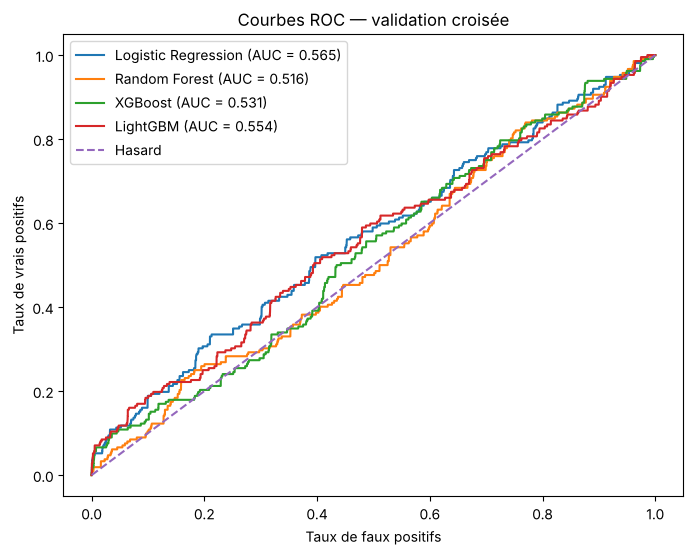

Modèle retenu : LightGBM


In [9]:
# Résumé des recherches Grid Search et écart train/validation
resultats_grid = pd.DataFrame(resultats_grid)
resultats_grid["Ecart_train_validation"] = (
    resultats_grid["Score_train_CV"] - resultats_grid["Average_Precision_CV"]
)
display(resultats_grid.sort_values("Average_Precision_CV", ascending=False))
print("Référence aléatoire (taux de défaut) :", round(y_train.mean(), 4))

# Prédictions hors pli pour comparer les quatre modèles de manière cohérente
probabilites_cv = {}
comparaison = []

for nom, modele in meilleurs_modeles.items():
    probabilites = cross_val_predict(
        modele, X_train, y_train, cv=cv, groups=groupes_train,
        method="predict_proba", n_jobs=1
    )[:, 1]
    probabilites_cv[nom] = probabilites
    predictions = (probabilites >= 0.5).astype(int)

    comparaison.append({
        "Modele": nom,
        "Accuracy": accuracy_score(y_train, predictions),
        "Precision": precision_score(y_train, predictions, zero_division=0),
        "Recall": recall_score(y_train, predictions, zero_division=0),
        "F1": f1_score(y_train, predictions, zero_division=0),
        "AUC": roc_auc_score(y_train, probabilites),
        "Average_Precision": average_precision_score(y_train, probabilites)
    })

comparaison = pd.DataFrame(comparaison).sort_values("Average_Precision", ascending=False)
display(comparaison)

# Courbes ROC des quatre modèles à partir des prédictions hors pli
plt.figure(figsize=(8, 6))
for nom, probabilites in probabilites_cv.items():
    fpr, tpr, _ = roc_curve(y_train, probabilites)
    auc = roc_auc_score(y_train, probabilites)
    plt.plot(fpr, tpr, label=f"{nom} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Hasard")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.title("Courbes ROC — validation croisée")
plt.legend()
plt.show()

# Choisir le meilleur modèle selon l'Average Precision hors pli
meilleur_nom = comparaison.iloc[0]["Modele"]
meilleur_modele = meilleurs_modeles[meilleur_nom]
print("Modèle retenu :", meilleur_nom)

#### Lecture des résultats — Étape 9

**1. Tous les modèles font mieux que le hasard, mais modestement.** Le hasard obtient une AP égale au taux de défaut, **0,0083**.

| Modèle | AP en validation croisée (moyenne ± écart-type) | Rapport au hasard |
|---|---|---|
| LightGBM | 0,031 ± 0,010 | environ 3,8 |
| Logistic Regression | 0,025 ± 0,007 | environ 3,1 |
| XGBoost | 0,021 ± 0,006 | environ 2,5 |
| Random Forest | 0,016 ± 0,006 | environ 1,9 |

**2. Les écarts entre modèles sont du même ordre que les écarts-types.** LightGBM (0,031 ± 0,010) et la régression logistique (0,025 ± 0,007) ne sont pas distinguables avec certitude : avec environ 70 défauts par pli, le hasard du découpage pèse autant que la différence entre modèles.

**3. Les modèles à base d'arbres surapprennent fortement.**
- LightGBM atteint une AP de **0,53 sur l'entraînement** contre 0,031 en validation, soit un écart de 0,49. XGBoost (écart de 0,42) et Random Forest (0,28) sont dans la même situation.
- La **régression logistique** a un écart de seulement **0,03** : elle généralise comme elle apprend.

C'est le revers de leur souplesse (étape 8) : ces modèles apprennent par cœur une partie des cas d'entraînement.

**4. Les prédictions hors pli, au seuil de 0,5.**
- Les **courbes ROC** sont proches de la diagonale du hasard, avec des AUC de **0,52 à 0,57**.
- **L'Accuracy est trompeuse.** LightGBM affiche 97,0 %, alors qu'un modèle qui ne signalerait aucun dossier atteindrait 99,2 %. La régression logistique n'affiche que 67,4 %, mais elle capte 41,5 % des défauts, car elle signale beaucoup plus de dossiers. Cela confirme que l'Accuracy n'est pas une métrique adaptée (étape 1).
- **Les métriques au seuil de 0,5 dépendent de ce seuil.** C'est pourquoi le choix du modèle repose sur l'Average Precision, qui n'en dépend pas, et que le seuil est choisi ensuite.

**5. Pourquoi deux valeurs d'AP ?** Le tableau du Grid Search donne la **moyenne des AP calculées pli par pli** (0,031 pour LightGBM). Le second tableau calcule l'AP **sur l'ensemble des prédictions hors pli réunies** (0,022). Les deux calculs diffèrent légèrement, mais ils classent les deux meilleurs modèles dans le même ordre.

**Le modèle retenu : LightGBM.** Il a la meilleure AP hors pli (0,0223), mais de très peu devant la régression logistique (0,0221). La régression logistique reste une **alternative tout aussi défendable** : presque aussi performante, sans surapprentissage et plus simple à expliquer.

### Étape 9 (suite) — Le modèle retenu avant le choix du seuil

> **Question :** comment se comporte le modèle retenu avec le seuil par défaut ?

**Pourquoi cette étape ?** Un modèle donne une **probabilité**. Pour décider (signaler ou non un dossier), il faut la comparer à un **seuil**. Par défaut, ce seuil vaut 0,5. Avant de l'optimiser, on regarde ce qu'il produit.

**Ce que fait le code.** Sur les prédictions hors pli du modèle retenu :
- la **matrice de confusion** au seuil 0,5 compte les défauts captés, les défauts manqués et les fausses alertes ;
- la **courbe ROC**, indépendante du seuil, résume la capacité du modèle à classer les défauts au-dessus des non-défauts, pour tous les seuils possibles.

Le jeu de test n'est toujours pas utilisé.

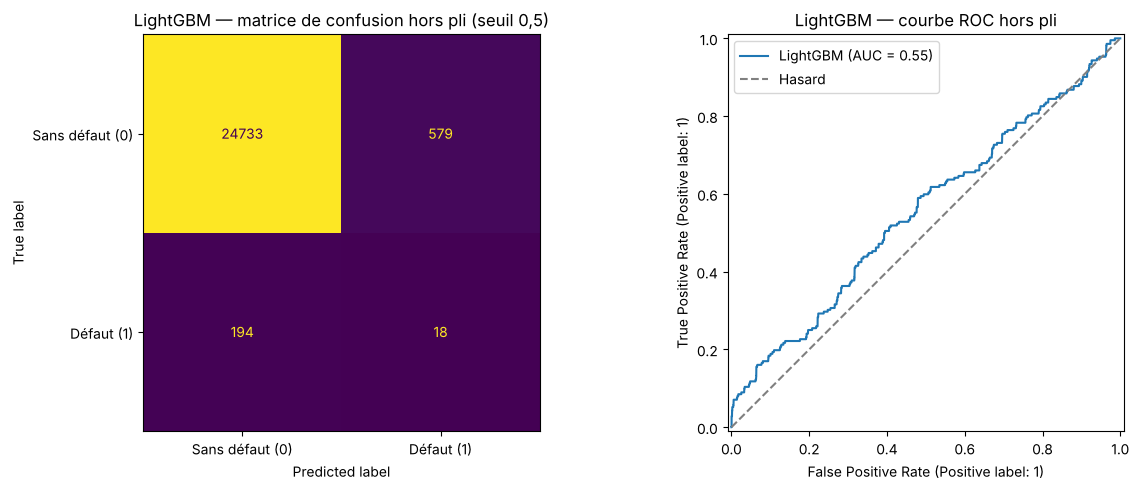

Avant optimisation du seuil (seuil 0,5, prédictions hors pli) :
Dossiers signalés : 597
Precision : 0.0302
Recall : 0.0849
F2 : 0.0623


In [10]:
probabilites_retenu_cv = probabilites_cv[meilleur_nom]
predictions_retenu_cv = (probabilites_retenu_cv >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(
    confusion_matrix(y_train, predictions_retenu_cv),
    display_labels=["Sans défaut (0)", "Défaut (1)"]
).plot(ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title(f"{meilleur_nom} — matrice de confusion hors pli (seuil 0,5)")

RocCurveDisplay.from_predictions(y_train, probabilites_retenu_cv, name=meilleur_nom, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Hasard")
axes[1].set_title(f"{meilleur_nom} — courbe ROC hors pli")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Avant optimisation du seuil (seuil 0,5, prédictions hors pli) :")
print("Dossiers signalés :", int(predictions_retenu_cv.sum()))
print("Precision :", round(precision_score(y_train, predictions_retenu_cv, zero_division=0), 4))
print("Recall :", round(recall_score(y_train, predictions_retenu_cv, zero_division=0), 4))
print("F2 :", round(fbeta_score(y_train, predictions_retenu_cv, beta=2, zero_division=0), 4))

#### Lecture des résultats — Le modèle retenu au seuil de 0,5

Sur les 25 524 lignes d'entraînement (prédictions hors pli) :
- **597 dossiers signalés**, dont seulement **18 vrais défauts** : 579 fausses alertes ;
- **194 défauts sur 212 ne sont pas détectés** : Recall de **8,5 %** ;
- Precision de **3,0 %** : moins d'un dossier signalé sur trente est un vrai défaut ;
- F2 de **0,062**.

La courbe ROC (AUC de **0,55**) reste proche de la diagonale.

**Ce que cela implique.** Le seuil de 0,5 n'a rien de naturel ici. La pondération des classes (étape 8) gonfle les probabilités de la classe défaut : 0,5 ne correspond plus à « une chance sur deux ». Le seuil doit donc être choisi selon un critère métier : c'est l'objet de l'étape suivante.

### Étape 9 (suite) — Choisir le seuil de décision

> **Question :** à partir de quel score faut-il signaler un dossier ?

**Pourquoi cette étape ?** Le seuil traduit un arbitrage métier. Un seuil bas signale beaucoup de dossiers et capte davantage de défauts, mais génère de nombreuses fausses alertes. Un seuil haut signale peu de dossiers, plus souvent à juste titre, mais laisse passer davantage de défauts.

**La règle de choix.** On retient le seuil qui **maximise le F2-score** sur les prédictions hors pli. Le F2 donne deux fois plus de poids au Recall qu'à la Precision : il traduit le coût plus élevé d'un défaut non détecté (étape 1). Cette pondération est à valider avec le métier.

**Ce que fait le code.** Il teste une centaine de seuils, correspondant à des parts de dossiers signalés allant de 50 % à 0,5 %. Pour chacun, il calcule la Precision, le Recall et le F2, puis retient le meilleur.

Le seuil est ensuite **figé** : le jeu de test ne sert pas à le choisir.

In [11]:
probabilites_meilleur_cv = probabilites_cv[meilleur_nom]
seuils = np.unique(np.quantile(probabilites_meilleur_cv, np.linspace(0.50, 0.995, 100)))
candidats = []

for seuil in seuils:
    predictions = (probabilites_meilleur_cv >= seuil).astype(int)
    candidats.append({
        "Seuil": seuil,
        "Dossiers_signales_%": round(predictions.mean() * 100, 2),
        "Precision": precision_score(y_train, predictions, zero_division=0),
        "Recall": recall_score(y_train, predictions, zero_division=0),
        "F2": fbeta_score(y_train, predictions, beta=2, zero_division=0)
    })

table_seuils = pd.DataFrame(candidats)
meilleur_seuil = float(table_seuils.sort_values("F2", ascending=False).iloc[0]["Seuil"])

print("Seuil retenu :", round(meilleur_seuil, 4))
display(table_seuils.sort_values("F2", ascending=False).head(10))

Seuil retenu : 0.6585


,Seuil,Dossiers_signales_%,Precision,Recall,F2
98,0.658525,1.00,0.058594,0.070755,0.067935
96,0.520383,2.02,0.034951,0.084906,0.066031
87,0.304884,6.51,0.019856,0.155660,0.065737
97,0.570594,1.50,0.041667,0.075472,0.064935
86,0.290026,7.00,0.019026,0.160377,0.064516
93,0.434409,3.51,0.024554,0.103774,0.063073
85,0.278337,7.52,0.017718,0.160377,0.061438
95,0.489358,2.51,0.028125,0.084906,0.060484
84,0.261256,8.02,0.017090,0.165094,0.060428
83,0.251808,8.50,0.016590,0.169811,0.059642


#### Lecture des résultats — Le seuil retenu

- Le seuil qui maximise le F2 est **0,6585**, **plus élevé que 0,5**. C'est une conséquence de la pondération des classes : comme les probabilités sont gonflées, le seuil remonte pour compenser.
- À ce seuil, en validation croisée, le modèle signale **1 % des dossiers**, avec une Precision de **5,9 %** et un Recall de **7,1 %** (F2 de **0,068**).
- **Les F2 des meilleurs seuils sont très proches** (de 0,060 à 0,068). On observe un plateau. Par exemple, un seuil de 0,30 signale 6,5 % des dossiers et capte 15,6 % des défauts, pour un F2 presque identique (0,066).

**Ce que cela implique.**
- Plusieurs seuils sont presque équivalents pour le critère choisi. Le seuil retenu privilégie un **faible nombre de dossiers signalés** : l'analyste examine peu de dossiers, mais plus souvent à juste titre.
- Si le métier préfère capter davantage de défauts, quitte à examiner plus de dossiers, il peut choisir un critère qui pèse encore plus le Recall (par exemple un F3) et recalculer le seuil ici, en validation croisée.

Le seuil est maintenant **figé** pour l'évaluation finale.

## Étape 10 — Évaluation finale, explicabilité et sauvegarde

> **Question :** que vaut réellement le modèle ?

**Pourquoi cette étape ?** Toutes les décisions sont prises : modèle, hyperparamètres, seuil. Le jeu de test, mis de côté à l'étape 7, donne maintenant une estimation **non biaisée** de la performance sur des clients jamais vus. Il est utilisé **une seule fois**.

**Ce que fait le code.**
- Il calcule les métriques sur le test, au seuil retenu.
- Il affiche la matrice de confusion pour le **seuil par défaut (0,5)** et pour le **seuil retenu**, ainsi que la courbe ROC du test. La comparaison illustre l'effet du seuil. Elle ne sert pas à le modifier, puisqu'il a été figé à l'étape 9.
- Il construit un tableau qui compare les deux seuils en nombres de dossiers.

,Modele,Seuil,Accuracy,Precision,Recall,F1,F2,AUC,Average_Precision,Taux_de_defaut_test
0,LightGBM,0.658525,0.985457,0.103448,0.1,0.101695,0.100671,0.588,0.046875,0.008232


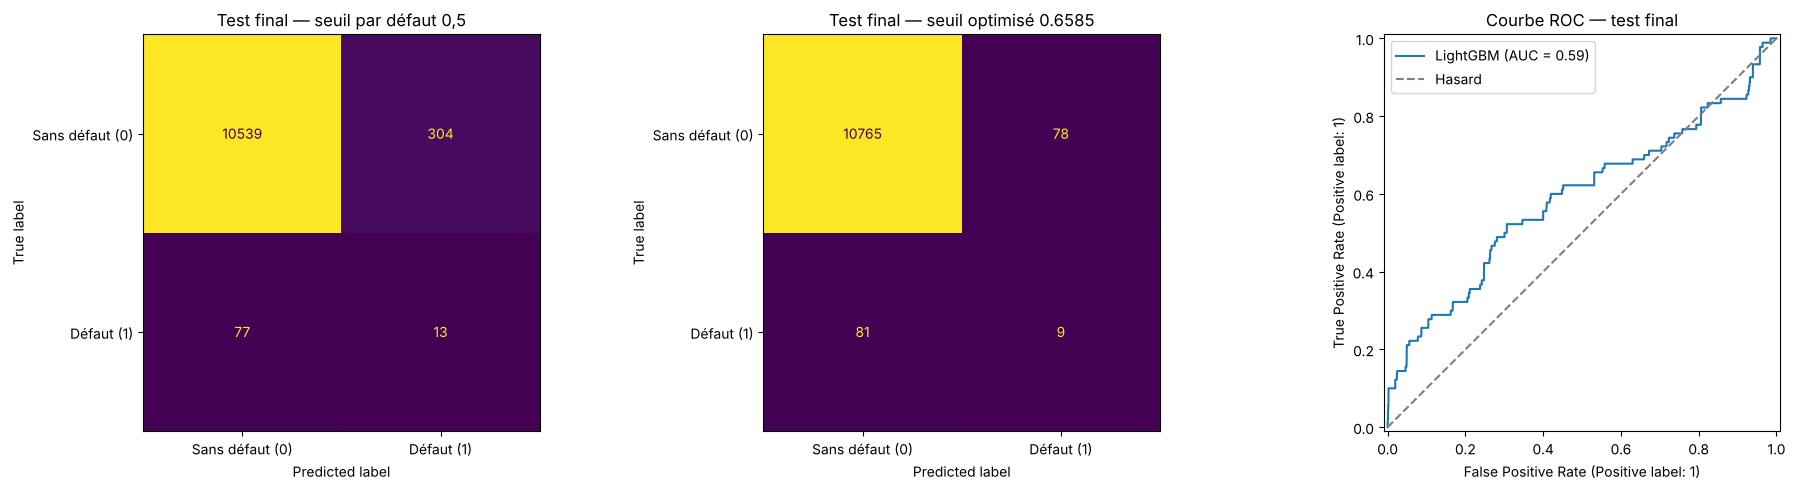

,Seuil,Valeur,Dossiers_signales,Vrais_defauts_captes,Faux_positifs,Defauts_manques,Precision,Recall,F2
0,Par défaut,0.5000,317,13,304,77,0.0410,0.1444,0.0960
1,Optimisé (F2),0.6585,87,9,78,81,0.1034,0.1000,0.1007


In [12]:
# GridSearchCV a déjà réentraîné le meilleur estimateur sur tout X_train.
probabilites_test = meilleur_modele.predict_proba(X_test)[:, 1]
predictions_test = (probabilites_test >= meilleur_seuil).astype(int)

metriques_finales = pd.DataFrame([{
    "Modele": meilleur_nom,
    "Seuil": meilleur_seuil,
    "Accuracy": accuracy_score(y_test, predictions_test),
    "Precision": precision_score(y_test, predictions_test, zero_division=0),
    "Recall": recall_score(y_test, predictions_test, zero_division=0),
    "F1": f1_score(y_test, predictions_test, zero_division=0),
    "F2": fbeta_score(y_test, predictions_test, beta=2, zero_division=0),
    "AUC": roc_auc_score(y_test, probabilites_test),
    "Average_Precision": average_precision_score(y_test, probabilites_test),
    "Taux_de_defaut_test": y_test.mean()
}])
display(metriques_finales)

# Comparaison sur le test : seuil par défaut (0,5) et seuil optimisé (figé à l'étape 9)
predictions_test_defaut = (probabilites_test >= 0.5).astype(int)
etiquettes = ["Sans défaut (0)", "Défaut (1)"]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (titre, predictions) in zip(axes[:2], [
    ("seuil par défaut 0,5", predictions_test_defaut),
    (f"seuil optimisé {meilleur_seuil:.4f}", predictions_test),
]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, predictions), display_labels=etiquettes).plot(
        ax=ax, values_format="d", colorbar=False
    )
    ax.set_title("Test final — " + titre)

RocCurveDisplay.from_predictions(y_test, probabilites_test, name=meilleur_nom, ax=axes[2])
axes[2].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Hasard")
axes[2].set_title("Courbe ROC — test final")
axes[2].legend()
plt.tight_layout()
plt.show()

lignes_seuils = []
for nom_seuil, seuil, predictions in [
    ("Par défaut", 0.5, predictions_test_defaut),
    ("Optimisé (F2)", meilleur_seuil, predictions_test),
]:
    vn, fp, fn, vp = confusion_matrix(y_test, predictions).ravel()
    lignes_seuils.append({
        "Seuil": nom_seuil,
        "Valeur": round(seuil, 4),
        "Dossiers_signales": int(predictions.sum()),
        "Vrais_defauts_captes": int(vp),
        "Faux_positifs": int(fp),
        "Defauts_manques": int(fn),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F2": fbeta_score(y_test, predictions, beta=2, zero_division=0)
    })
comparaison_seuils = pd.DataFrame(lignes_seuils)
display(comparaison_seuils.round(4))

#### Lecture des résultats — Évaluation finale sur le test

**Performance du modèle sur des clients jamais vus** (10 933 demandes, dont 90 défauts) :
- **AUC de 0,588** : le modèle classe un défaut au-dessus d'un non-défaut dans environ 59 % des cas.
- **Average Precision de 0,047**, soit environ **5,7 fois** le taux de défaut du test (0,82 %).
- Au seuil retenu : **Precision de 10,3 %**, **Recall de 10,0 %**, **F2 de 0,101**.
- L'**Accuracy de 98,5 %** n'a pas de sens ici (étape 1).

**Cohérence avec la validation croisée.** L'AUC du test (0,588) est du même ordre que l'AUC hors pli (0,55). L'écart s'explique par le faible nombre de défauts du test (90) : quelques cas suffisent à faire varier les métriques. Le test confirme donc l'estimation faite à l'étape 9.

**Effet du seuil, en nombres de dossiers :**

| Seuil | Dossiers signalés | Vrais défauts captés | Fausses alertes | Precision | Recall | F2 |
|---|---|---|---|---|---|---|
| 0,5 (par défaut) | 317 | 13 | 304 | 4,1 % | 14,4 % | 0,096 |
| 0,6585 (retenu) | 87 | 9 | 78 | 10,3 % | 10,0 % | 0,101 |

- Le seuil retenu **divise par quatre les fausses alertes** : l'analyste examine 87 dossiers au lieu de 317.
- **Un dossier signalé sur dix** est un vrai défaut, contre un sur vingt-cinq au seuil de 0,5.
- Le Recall baisse de 14 % à 10 %, soit **4 défauts sur 90** : un écart trop faible pour être significatif.
- Le F2, critère fixé à l'étape 9, est équivalent, voire légèrement meilleur.

Le test confirme donc l'intérêt du seuil choisi en validation croisée.

### Étape 10 (suite) — Explicabilité SHAP, client par client

> **Question :** sur quoi le modèle s'appuie-t-il pour décider ?

**Pourquoi cette étape ?** En crédit, une recommandation doit pouvoir être expliquée : à l'analyste qui examine le dossier, au client qui demande pourquoi, et à un contrôleur. LightGBM n'est pas lisible directement : SHAP (*SHapley Additive exPlanations*) le rend explicable.

**Le principe.** Pour chaque client, SHAP répartit le score entre les variables :
- une contribution **positive** augmente le risque estimé ;
- une contribution **négative** le diminue ;
- les contributions partent du score moyen du modèle et s'additionnent pour donner le score du client. Elles sont exprimées en *log-odds*, l'échelle interne du modèle avant la conversion en probabilité.

**Deux niveaux de lecture.**
- **Vue globale** : la contribution moyenne (en valeur absolue) de chaque variable sur tout le jeu de test, c'est-à-dire ce sur quoi le modèle s'appuie en général.
- **Vue locale** : la fonction `expliquer_client(position)` explique un dossier précis, avec le sens et l'intensité de chaque facteur.

Les colonnes créées par le one-hot encoding (étape 5) sont additionnées pour revenir aux **variables d'origine** : toutes les colonnes `NAME_INCOME_TYPE_...` deviennent `NAME_INCOME_TYPE`. L'explication reste ainsi lisible pour un analyste.

La cellule se termine par la **sauvegarde** du modèle, du seuil, de la liste des colonnes et des résultats dans `models/`. L'application les utilise sans réentraîner le modèle.

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


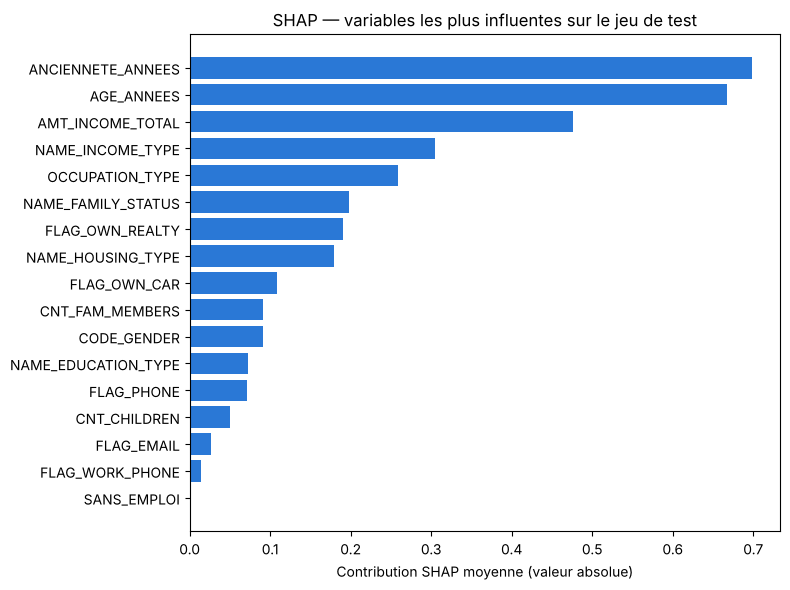

Client n°10858 du test
Probabilité estimée : 0.966 | seuil : 0.659
Décision : dossier à examiner
Défaut réellement observé : oui


,Variable,Valeur du client,Contribution SHAP,Effet
0,AMT_INCOME_TOTAL,108000.0,1.761,augmente le risque
1,NAME_INCOME_TYPE,Pensioner,0.943,augmente le risque
2,AGE_ANNEES,60.8,0.931,augmente le risque
3,ANCIENNETE_ANNEES,0.0,0.902,augmente le risque
4,FLAG_OWN_REALTY,N,0.543,augmente le risque
5,NAME_FAMILY_STATUS,Widow,0.420,augmente le risque
6,CODE_GENDER,M,0.345,augmente le risque
7,OCCUPATION_TYPE,Inconnu,0.296,augmente le risque


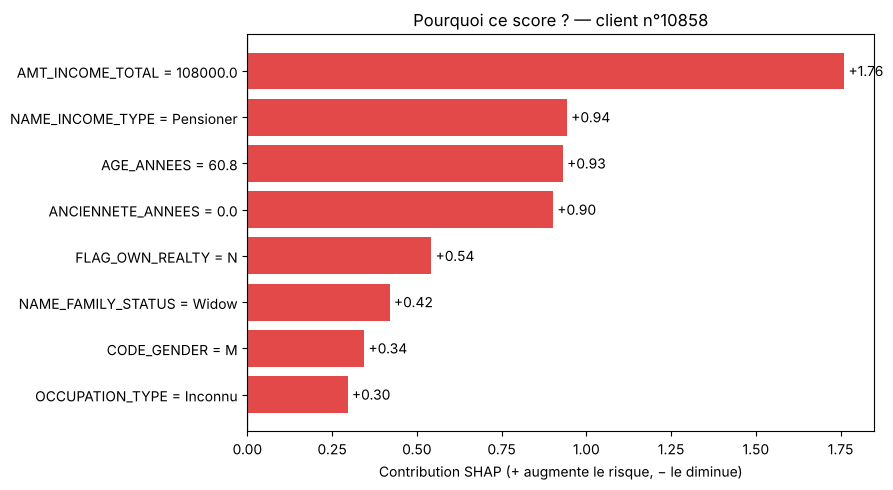

Client n°2999 du test
Probabilité estimée : 0.000 | seuil : 0.659
Décision : dossier non signalé
Défaut réellement observé : non


,Variable,Valeur du client,Contribution SHAP,Effet
0,AGE_ANNEES,64.4,-3.304,diminue le risque
1,ANCIENNETE_ANNEES,14.1,-2.648,diminue le risque
2,OCCUPATION_TYPE,Cleaning staff,-1.070,diminue le risque
3,AMT_INCOME_TOTAL,450000.0,-0.472,diminue le risque
4,FLAG_OWN_REALTY,Y,-0.184,diminue le risque
5,CODE_GENDER,F,-0.151,diminue le risque
6,NAME_INCOME_TYPE,Working,-0.124,diminue le risque
7,NAME_EDUCATION_TYPE,Secondary / secondary special,0.118,augmente le risque


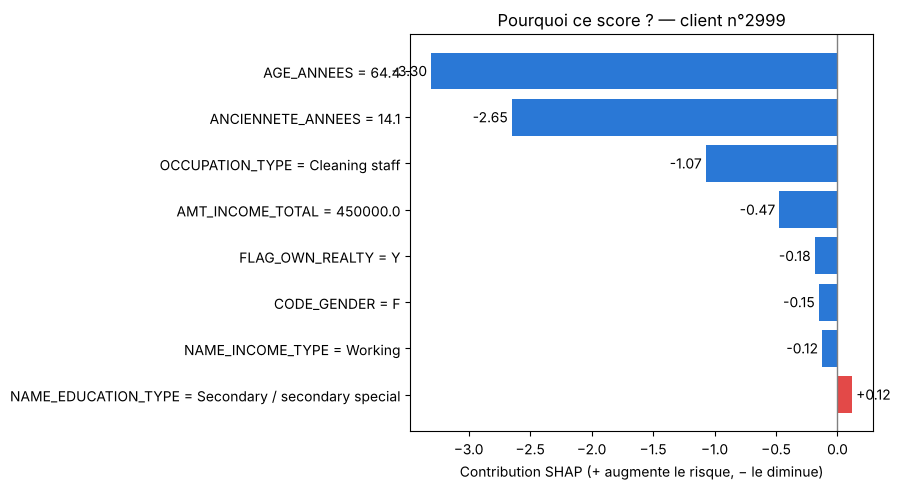

Modèle, seuil et résultats sauvegardés dans models/.


In [13]:
# Données de test transformées par le prétraitement du modèle retenu
preparation_finale = meilleur_modele.named_steps["preparation"]
modele_final = meilleur_modele.named_steps["modele"]

X_test_prep = preparation_finale.transform(X_test)
if hasattr(X_test_prep, "toarray"):
    X_test_prep = X_test_prep.toarray()

# Variable d'origine de chaque colonne après encodage
encodeur = preparation_finale.named_transformers_["categorielle"].named_steps["encodage"]
variables_origine = list(colonnes_num)
for colonne, categories in zip(colonnes_cat, encodeur.categories_):
    variables_origine += [colonne] * len(categories)

# Calcul des valeurs SHAP adapté au type de modèle
if isinstance(modele_final, LogisticRegression):
    X_train_prep = preparation_finale.transform(X_train)
    if hasattr(X_train_prep, "toarray"):
        X_train_prep = X_train_prep.toarray()
    explainer = shap.LinearExplainer(modele_final, X_train_prep)
else:
    explainer = shap.TreeExplainer(modele_final)

valeurs_shap = explainer.shap_values(X_test_prep)
if isinstance(valeurs_shap, list):          # une sortie par classe : on garde la classe défaut
    valeurs_shap = valeurs_shap[1]
if np.ndim(valeurs_shap) == 3:              # Random Forest : (clients, colonnes, classes)
    valeurs_shap = valeurs_shap[:, :, 1]

# Regroupement des colonnes one-hot par variable d'origine
shap_variables = pd.DataFrame(valeurs_shap).T.groupby(variables_origine).sum().T
shap_variables.index = X_test.index

# Vue globale : contribution moyenne (en valeur absolue) de chaque variable
importance_shap = shap_variables.abs().mean().sort_values(ascending=False)
plt.figure(figsize=(8, 6))
plt.barh(importance_shap.index[::-1], importance_shap.values[::-1], color="#2a78d6")
plt.xlabel("Contribution SHAP moyenne (valeur absolue)")
plt.title("SHAP — variables les plus influentes sur le jeu de test")
plt.tight_layout()
plt.show()


def expliquer_client(position, nb_variables=8):
    # Explique le score d'un client du jeu de test (position de 0 à len(X_test) - 1)
    probabilite = probabilites_test[position]
    signale = probabilite >= meilleur_seuil
    print(f"Client n°{position} du test")
    print(f"Probabilité estimée : {probabilite:.3f} | seuil : {meilleur_seuil:.3f}")
    print("Décision :", "dossier à examiner" if signale else "dossier non signalé")
    print("Défaut réellement observé :", "oui" if y_test.iloc[position] == 1 else "non")

    contributions = shap_variables.iloc[position]
    valeurs_client = X_test.iloc[position].astype(object).where(X_test.iloc[position].notna(), "Inconnu")
    table = pd.DataFrame({
        "Variable": contributions.index,
        "Valeur du client": valeurs_client[contributions.index].values,
        "Contribution SHAP": contributions.values.round(3)
    })
    table["Effet"] = np.where(table["Contribution SHAP"] > 0, "augmente le risque", "diminue le risque")
    table = table.loc[table["Contribution SHAP"].abs().sort_values(ascending=False).index].head(nb_variables)
    display(table.reset_index(drop=True))

    # Graphique : rouge = augmente le risque, bleu = diminue le risque
    graphique = table.iloc[::-1]
    couleurs = np.where(graphique["Contribution SHAP"] > 0, "#e34948", "#2a78d6")
    etiquettes = graphique["Variable"] + " = " + graphique["Valeur du client"].astype(str)
    plt.figure(figsize=(9, 5))
    barres = plt.barh(etiquettes, graphique["Contribution SHAP"], color=couleurs)
    plt.bar_label(barres, labels=[f"{v:+.2f}" for v in graphique["Contribution SHAP"]], padding=3)
    plt.axvline(0, color="grey", linewidth=1)
    plt.xlabel("Contribution SHAP (+ augmente le risque, − le diminue)")
    plt.title(f"Pourquoi ce score ? — client n°{position}")
    plt.tight_layout()
    plt.show()


# Exemple 1 : le défaut réel du test qui a reçu le score le plus élevé
positions_defauts = np.where(y_test.values == 1)[0]
expliquer_client(positions_defauts[np.argmax(probabilites_test[positions_defauts])])

# Exemple 2 : le client du test qui a reçu le score le plus faible
expliquer_client(int(np.argmin(probabilites_test)))


# Sauvegarde du modèle, du seuil et des résultats
importance_shap_table = importance_shap.rename_axis("Variable").reset_index(name="Importance_SHAP_moyenne")

os.makedirs("models", exist_ok=True)
joblib.dump(meilleur_modele, "models/modele_scoring_credit.joblib")
joblib.dump(meilleur_seuil, "models/seuil_decision.joblib")
joblib.dump(list(X.columns), "models/colonnes_modele.joblib")
comparaison.to_csv("models/comparaison_modeles_cv.csv", index=False)
resultats_grid.to_csv("models/resultats_grid_search.csv", index=False)
metriques_finales.to_csv("models/metriques_test_final.csv", index=False)
comparaison_seuils.to_csv("models/comparaison_seuils_test.csv", index=False)
importance_shap_table.to_csv("models/importance_shap.csv", index=False)

print("Modèle, seuil et résultats sauvegardés dans models/.")

#### Lecture des résultats — Explicabilité SHAP

**Vue globale : les variables qui pèsent le plus.**
1. **Ancienneté dans l'emploi** ;
2. **Âge** ;
3. **Revenu annuel** ;
4. **Type de revenu** ;
5. **Métier**.

Viennent ensuite la situation familiale, la propriété d'un bien immobilier et le type de logement. Ce classement est cohérent avec un raisonnement de crédit : stabilité professionnelle, âge et ressources.

**Lien avec l'EDA.** `SANS_EMPLOI` a une contribution presque nulle. Ce n'est pas une information inutile : elle est déjà portée par `NAME_INCOME_TYPE` (valeur « retraité ») et par une ancienneté égale à 0. L'EDA avait montré que ces 6 135 clients sont tous des retraités : le modèle utilise l'information par un autre chemin.

**Vue locale : deux clients.**
- **Client n°10858**, un vrai défaut, score de **0,966** (dossier signalé). Tous les facteurs principaux augmentent son risque :
  - revenu de 108 000 ;
  - statut de retraité ;
  - 61 ans ;
  - aucune ancienneté dans l'emploi ;
  - pas de bien immobilier ;
  - veuvage.
- **Client n°2999**, pas de défaut, score proche de **0** (dossier non signalé). Ce sont surtout ses **64 ans** et ses **14 ans d'ancienneté** qui font baisser son risque.

**Une même variable peut jouer dans les deux sens.** L'âge augmente le risque du premier client et diminue fortement celui du second, alors qu'ils ont presque le même âge. La différence vient de leur situation : le premier est retraité sans ancienneté, le second est en emploi depuis 14 ans. Le modèle combine les variables entre elles. C'est ce qu'annonçait l'EDA : aucune variable seule n'explique le défaut.

**Point de vigilance.** `CODE_GENDER` apparaît dans certaines explications individuelles, avec un poids faible. Utiliser le sexe pour une décision de crédit pose un problème de non-discrimination : voir les pistes d'amélioration de la conclusion.

**Sauvegarde.** Le modèle, le seuil, la liste des 17 colonnes et les tableaux de résultats sont enregistrés dans `models/`. L'application les utilise directement (étape 11).

## Conclusion

**Ce que le projet a construit.** Une chaîne complète et reproductible :
- construction de la cible à partir de l'historique de crédit ;
- analyse et préparation des données ;
- découpage sans fuite grâce aux groupes de profils ;
- comparaison de quatre modèles optimisés par Grid Search ;
- choix d'un seuil métier, évaluation unique sur un test indépendant ;
- explication des décisions avec SHAP.

**Ce que valent les résultats.**
- Le modèle retenu, **LightGBM**, obtient sur le test une AUC de **0,588** et une Average Precision de **0,047**, soit environ **5,7 fois** le taux de défaut (0,82 %). Il fait donc nettement mieux que le hasard pour classer les dossiers.
- Au seuil retenu (**0,6585**), il signale **87 dossiers** sur 10 933. **Un sur dix** est un vrai défaut, contre moins d'un sur cent au hasard. Il capte **10 %** des défauts.
- Comparé au seuil par défaut de 0,5, le seuil retenu **divise par quatre les fausses alertes** (78 contre 304) et multiplie la Precision par 2,5 (10,3 % contre 4,1 %), pour un F2 équivalent (0,101 contre 0,096). La baisse du Recall (10 % contre 14 %) porte sur 4 défauts sur 90.

**Bonne pratique sur le seuil.** Le seuil est fixé en validation croisée, puis figé. Le changer après avoir vu le test reviendrait à l'optimiser sur le test, ce qui fausserait l'évaluation. Si le métier estime qu'un défaut non détecté coûte encore plus cher, il faut modifier le critère (par exemple un F3) et recalculer le seuil en validation croisée.

**Limite principale.** Quel que soit le seuil, le modèle ne capte qu'une petite partie des défauts. Les informations disponibles au moment de la demande (profil, revenu, emploi) prédisent mal le défaut grave, comme l'annonçaient déjà les corrélations très faibles de l'EDA. Le modèle aide donc à **prioriser les dossiers à examiner**. Il ne doit pas décider seul.

**Pistes d'amélioration.**
- Élargir la cible aux retards de 60 jours ou plus (statut `2`), ce qui double le nombre de défauts disponibles pour l'apprentissage.
- Ajouter des données de comportement de paiement ou de montant de crédit, absentes de ce jeu de données.
- Comparer en détail avec la régression logistique : presque aussi performante, elle ne surapprend pas et elle est plus simple à expliquer.
- Retirer `CODE_GENDER` des variables, ou vérifier l'équité des recommandations entre femmes et hommes : le sexe ne doit pas peser dans une décision de crédit.

*Les valeurs citées sont celles obtenues lors de l'exécution de ce notebook (graine aléatoire fixée à 42) ; elles peuvent varier légèrement avec d'autres versions des librairies.*

## Étape 11 — Streamlit : l'application NovaScore

> **Question :** comment le modèle est-il mis à disposition du métier ?

**Pourquoi cette étape ?** Un modèle n'a de valeur que s'il est utilisé. L'application `app.py` met le modèle sauvegardé à l'étape 10 entre les mains des analystes, sous la forme d'un outil d'aide à la décision.

**Le lien avec le notebook.**
- **Le modèle** : l'application charge `models/modele_scoring_credit.joblib`. Ce fichier contient le pipeline complet (préparation de l'étape 5 et LightGBM de l'étape 8) : les nouvelles demandes sont donc traitées exactement comme les données d'entraînement.
- **Les variables** : elle construit les mêmes variables qu'à l'étape 6 (âge en années, ancienneté, indicateur sans emploi), en suivant `models/colonnes_modele.joblib`.
- **Le seuil** : elle lit `models/seuil_decision.joblib` (étape 9). Un score au-dessus du seuil donne « Refus recommandé – dossier à examiner par un analyste », sinon « Accord recommandé ».
- **L'explication** : elle affiche, pour chaque demande, les facteurs SHAP de l'étape 10 avec leur valeur et un niveau d'impact fixe (Très fort ≥ 1 ; Fort 0,5 à 1 ; Modéré 0,2 à 0,5 ; Faible < 0,2).
- **L'assistant d'explication** : un modèle de langage (Claude) traduit ces facteurs en explication simple, liste les points à vérifier et propose un commentaire. Il ne reçoit que le score, le seuil et les facteurs, sans donnée d'identification, et ne décide jamais. Sa réponse est contrôlée (chiffres, formules de décision) ; à défaut, une explication automatique rédigée par des règles fixes la remplace.

**Les fonctions de l'application.**
- **Connexion** par identifiant et mot de passe. Au premier lancement, le compte `admin` / `admin` est créé automatiquement. Les mots de passe sont enregistrés chiffrés (PBKDF2).
- **Tableau de bord** : indicateurs et graphiques calculés à partir des demandes enregistrées.
- **Nouvelle demande** :
  - formulaire obligatoire, avec les champs manquants signalés ;
  - recommandation, score de risque sur 100, facteurs SHAP et explication de l'assistant ;
  - décision de l'analyste, modifiable avant l'enregistrement.
- **Historique** : filtres, export CSV, détail des demandes et correction d'une décision avec motif obligatoire.
- **Utilisateurs** (administrateurs uniquement) : création, modification et suppression des comptes.

Les comptes, les demandes et le suivi des décisions sont stockés dans la base **PostgreSQL**, schéma `app`. L'application s'y connecte avec le rôle `novascore_app`, qui ne peut ni lire les données sources, ni supprimer une demande, ni modifier le suivi des décisions. **La décision finale appartient toujours à l'analyste.**

**Important :** exécuter le notebook en entier avant de lancer l'application, pour que le dossier `models/` soit à jour.

## Étape 12 — Lancer l'application en local

Dans le terminal VS Code, avec l'environnement `novalis` activé et depuis le dossier du projet :

```cmd
python -m pip install -r requirements.txt
streamlit run app.py
```

Le navigateur ouvre l'application, en général à l'adresse http://localhost:8501. On se connecte avec `admin` / `admin`.